┌ Info: Saved animation to /Users/jayrajbandal/fun/funjl/pendulum.gif
└ @ Plots /Users/jayrajbandal/.julia/packages/Plots/AE0LB/src/animation.jl:156


Plots.AnimatedGif("/Users/jayrajbandal/fun/funjl/pendulum.gif")
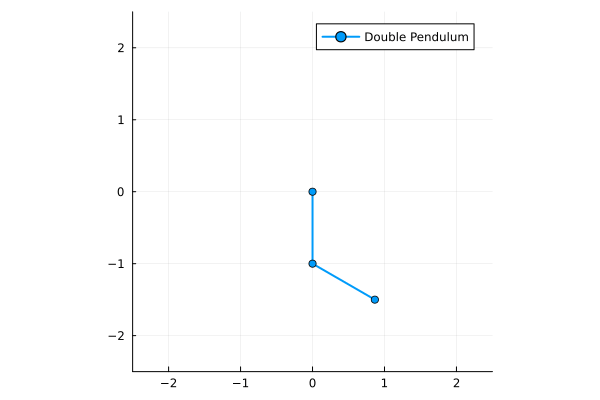

In [1]:
using DifferentialEquations
using Plots

# 1. Physical Constants
const m1, m2 = 2.0, 3.0
const l1, l2 = 1.0, 1.0
const g = 9.8

# 2. Define the Equations of Motion
# In Julia, the derivative function is (du, u, p, t)
function double_pendulum!(du, u, p, t)
    th1, th2, w1, w2 = u
    
    # Mass matrix / terms from Lagrangian simplification
    Δ = th2 - th1
    
    # Denominator term common in double pendulum equations
    den1 = (m1 + m2) * l1 - m2 * l1 * cos(Δ)^2
    den2 = (l2 / l1) * den1
    
    # angular velocity derivatives (dw1, dw2)
    du[1] = w1
    du[2] = w2
    
    du[3] = (m2 * l1 * w1^2 * sin(Δ) * cos(Δ) +
             m2 * g * sin(th2) * cos(Δ) +
             m2 * l2 * w2^2 * sin(Δ) -
             (m1 + m2) * g * sin(th1)) / den1

    du[4] = (-m2 * l2 * w2^2 * sin(Δ) * cos(Δ) +
             (m1 + m2) * g * sin(th1) * cos(Δ) -
             (m1 + m2) * l1 * w1^2 * sin(Δ) -
             (m1 + m2) * g * sin(th2)) / den2
end

# 3. Initial Conditions and Time Span
u0 = [0, pi/3, 0.0, 3.0]  # th1, th2, w1, w2
tspan = (0.0, 20.0)

# 4. Solve
prob = ODEProblem(double_pendulum!, u0, tspan)
# abstol/reltol are equivalent to rtol in scipy
sol = solve(prob, RK4(), reltol=1e-9, abstol=1e-9)

# 5. Extract and Plot (Smooth by default via sol object)
t_smooth = range(0, 20, length=1000)
data = sol(t_smooth)

th1_vals = data[1, :]
th2_vals = data[2, :]

# Calculate Cartesian coordinates for animation
x1 = l1 .* sin.(th1_vals)
y1 = -l1 .* cos.(th1_vals)
x2 = x1 .+ l2 .* sin.(th2_vals)
y2 = y1 .- l2 .* cos.(th2_vals)

# 6. Simple Animation
anim = @animate for i in 1:length(t_smooth)
    plot([0, x1[i], x2[i]], [0, y1[i], y2[i]], 
         marker=:circle, linewidth=2, xlim=(-2.5, 2.5), ylim=(-2.5, 2.5),
         label="Double Pendulum", aspect_ratio=:equal, grid=true)
end

gif(anim, "pendulum.gif", fps=50)

In [2]:
import Pkg
Pkg.add(["DifferentialEquations", "Plots"])

using DifferentialEquations
using Plots

    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
   Installed OrdinaryDiffEqRosenbrock ──────────── v1.27.0
   Installed OrdinaryDiffEqPRK ─────────────────── v1.9.0
   Installed OrdinaryDiffEqAdamsBashforthMoulton ─ v1.10.0
   Installed OrdinaryDiffEqSDIRK ───────────────── v1.13.0
   Installed OrdinaryDiffEqRKN ─────────────────── v1.11.0
   Installed FastGaussQuadrature ───────────────── v1.1.0
   Installed DifferentialEquations ─────────────── v8.0.0
   Installed OrdinaryDiffEqStabilizedRK ────────── v1.9.0
   Installed libva_jll ─────────────────────────── v2.23.0+0
   Installed OrdinaryDiffEqSSPRK ───────────────── v1.12.0
   Installed Xorg_libpciaccess_jll ─────────────── v0.19.0+0
   Installed OrdinaryDiffEqFIRK ────────────────── v1.24.0
   Installed OrdinaryDiffEqVerner ──────────────── v1.12.0
   Installed OrdinaryDiffEqNonlinearSolve ──────── v1.24.0
   Installed SparseMatrixColorings ─────────────── v0.4.27
   Installed OrdinaryD